# CyberSentryFusion
## Explainable Machine Learning for Network Intrusion Detection

**Purpose:** Build, compare, evaluate, and explain ML models that classify network-traffic records as **Normal (0)** or **Attack (1)**.

This is a learning-first notebook. Each stage includes readable code and comments explaining *what* we do and *why* we do it.

### What this notebook covers
1. Load the UNSW-NB15 train/test CSV files.
2. Inspect data quality, class balance, distributions, and correlations.
3. Create a leakage-aware train/validation/test workflow.
4. Build preprocessing with `ColumnTransformer`, `StandardScaler`, and `OneHotEncoder`.
5. Establish a DummyClassifier baseline.
6. Compare Logistic Regression, Decision Tree, Random Forest, and Extra Trees.
7. Evaluate with precision, recall, F1, confusion matrices, ROC-AUC, and PR-AUC.
8. Tune a selected model using cross-validation.
9. Study classification thresholds and false-positive/false-negative trade-offs.
10. Explain model behaviour with permutation importance and optional SHAP.
11. Inspect misclassified examples.
12. Refit the selected pipeline and save it for the Streamlit app.

> **Important:** This dataset contains labelled records, not a live network feed. A prediction on an uploaded CSV is only meaningful when its columns represent the same features and use compatible definitions. This project is an educational IDS prototype, not a production security appliance.

## 0. Learning and experiment rules

- Read a section before running it. Try to explain the code in your own words.
- Start with a small sample while developing; use the full data for final experiments.
- Never fit scalers or encoders on validation/test rows. A scikit-learn `Pipeline` keeps fitting inside the training fold.
- Use validation data to compare models, tune settings, and choose a threshold.
- Keep the official test set untouched until the final evaluation.
- Accuracy alone is not enough: missing an attack and incorrectly flagging normal traffic have different costs.
- Runtime can vary on Kaggle. If a cell is too slow, reduce `SEARCH_ITERATIONS`, `CV_FOLDS`, or use a stratified development sample. Record any sample-based result honestly.

## 1. Import libraries and set reproducibility

We use pandas for tables, NumPy for numerical operations, Matplotlib/Seaborn for visualizations, and scikit-learn for preprocessing, modelling, and evaluation.

`RANDOM_STATE` makes random splits and model randomness repeatable where supported.

In [3]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
sns.set_theme()  # default plotting theme

print("Libraries imported. Random state:", RANDOM_STATE)

Libraries imported. Random state: 42


## 2. Load the dataset





In [4]:
.
DATA_DIR = Path("/kaggle/input/datasets/uzairsidd/cyber-sentry-dataset")

TRAIN_PATH = DATA_DIR / "UNSW_NB15_training-set.csv"
TEST_PATH = DATA_DIR / "UNSW_NB15_testing-set.csv"


if not TRAIN_PATH.exists() or not TEST_PATH.exists():
    print("Expected paths were not found. Available CSV files under /kaggle/input:")
    for path in Path("/kaggle/input").rglob("*.csv"):
        print(path)

train_raw = pd.read_csv(TRAIN_PATH)
test_raw = pd.read_csv(TEST_PATH)

print("Training shape:", train_raw.shape)
print("Test shape:", test_raw.shape)
display(train_raw.head())

Training shape: (175341, 45)
Test shape: (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


## 3. First inspection: schema, types, and missing values

A row is one labelled traffic record. The target column `label` is 0 for Normal and 1 for Attack in this dataset.

We inspect the schema before modelling. Column names and definitions must be understood before deciding which ones are model inputs.

In [5]:
print("Training columns:")
print(train_raw.columns.tolist())

print("\nTraining data types:")
display(train_raw.dtypes.value_counts().rename_axis("dtype").to_frame("column_count"))

print("\nMissing values in training data (top 15):")
display(train_raw.isna().sum().sort_values(ascending=False).head(15).to_frame("missing_count"))

print("\nDuplicate rows in training file:", train_raw.duplicated().sum())
print("Duplicate rows in test file:", test_raw.duplicated().sum())

assert "label" in train_raw.columns, "The training file must contain a 'label' target column."
assert "label" in test_raw.columns, "The test file must contain a 'label' target column."

Training columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

Training data types:


,column_count
dtype,
int64,30
float64,11
object,4



Missing values in training data (top 15):


,missing_count
id,0
dur,0
proto,0
service,0
state,0
spkts,0
dpkts,0
sbytes,0
dbytes,0
rate,0



Duplicate rows in training file: 0
Duplicate rows in test file: 0


## 4. Check the target and class balance

Class balance tells us how common each class is. If one class is much more common, a model can appear accurate by mostly predicting that class.

The labels are:
- `0` → Normal
- `1` → Attack

We verify the actual values rather than assuming.

Training target values: [0, 1]
Test target values: [0, 1]


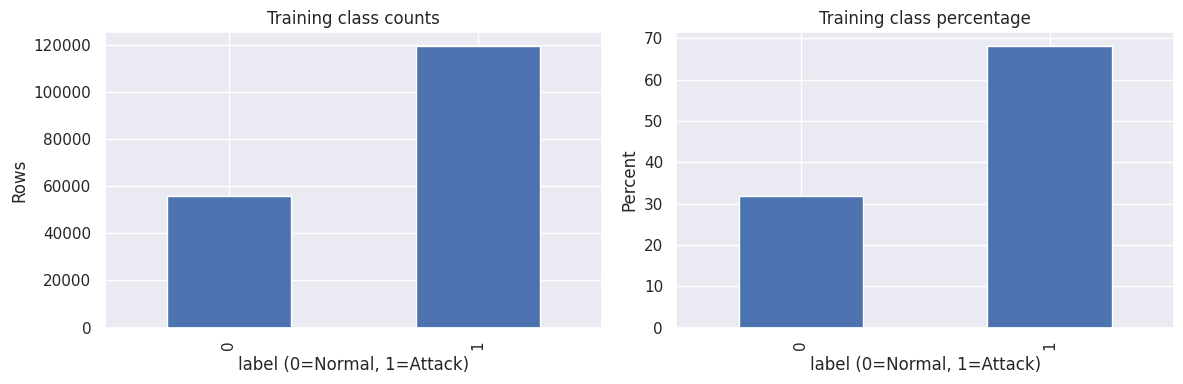

In [6]:
print("Training target values:", sorted(train_raw["label"].dropna().unique().tolist()))
print("Test target values:", sorted(test_raw["label"].dropna().unique().tolist()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train_raw["label"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Training class counts")
axes[0].set_xlabel("label (0=Normal, 1=Attack)")
axes[0].set_ylabel("Rows")

(train_raw["label"].value_counts(normalize=True).sort_index() * 100).plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Training class percentage")
axes[1].set_xlabel("label (0=Normal, 1=Attack)")
axes[1].set_ylabel("Percent")

plt.tight_layout()
plt.show()

## 5. Data quality checks

Duplicates can occur in network datasets. A duplicate is not automatically wrong: repeated traffic patterns may be legitimate. But exact duplicates and train/test overlap can make evaluation look more optimistic if the same records appear on both sides.

We report duplicates and exact train/test overlap. We do **not** automatically delete every duplicate, because that decision should be justified and documented. Also, do not use these diagnostics to repeatedly tune against the test set.

In [7]:
# Exact row overlap on columns shared by both files.
shared_columns = [c for c in train_raw.columns if c in test_raw.columns]
train_shared = train_raw[shared_columns].drop_duplicates()
test_shared = test_raw[shared_columns].drop_duplicates()

train_hashes = pd.util.hash_pandas_object(train_shared, index=False)
test_hashes = pd.util.hash_pandas_object(test_shared, index=False)
overlap_hashes = set(train_hashes).intersection(set(test_hashes))

print("Unique training rows on shared columns:", len(train_shared))
print("Unique test rows on shared columns:", len(test_shared))
print("Approximate exact-row hash overlap:", len(overlap_hashes))
print("Note: overlap is a diagnostic, not a reason to tune on the test set.")

Unique training rows on shared columns: 175341
Unique test rows on shared columns: 82332
Approximate exact-row hash overlap: 0
Note: overlap is a diagnostic, not a reason to tune on the test set.


## 6. Exploratory data analysis (EDA)

We explore numeric features, categorical values, and the relationship between selected features and the label.

EDA is for understanding the data and spotting potential issues. It is not proof that a feature causes an attack.

Numeric features available for EDA: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'ct_state_ttl']


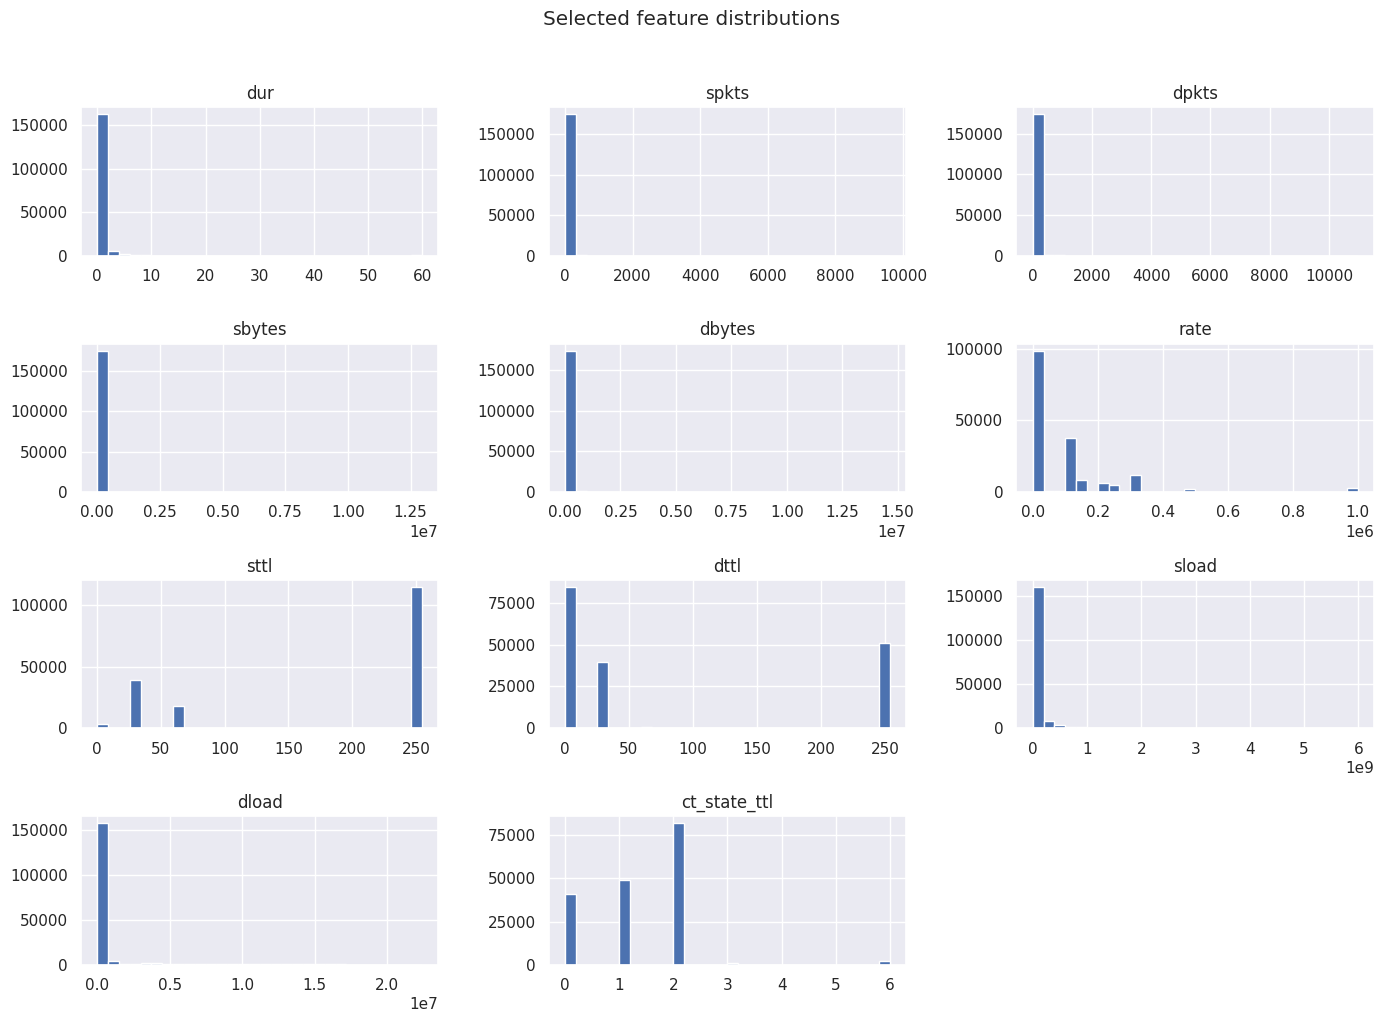

In [8]:
# Use the target and a few commonly available numeric features for readable plots.
candidate_numeric = [
    "dur", "spkts", "dpkts", "sbytes", "dbytes", "rate",
    "sttl", "dttl", "sload", "dload", "ct_state_ttl"
]
available_numeric = [c for c in candidate_numeric if c in train_raw.columns]

print("Numeric features available for EDA:", available_numeric)

if available_numeric:
    train_raw[available_numeric].hist(figsize=(14, 10), bins=30)
    plt.suptitle("Selected feature distributions", y=1.02)
    plt.tight_layout()
    plt.show()

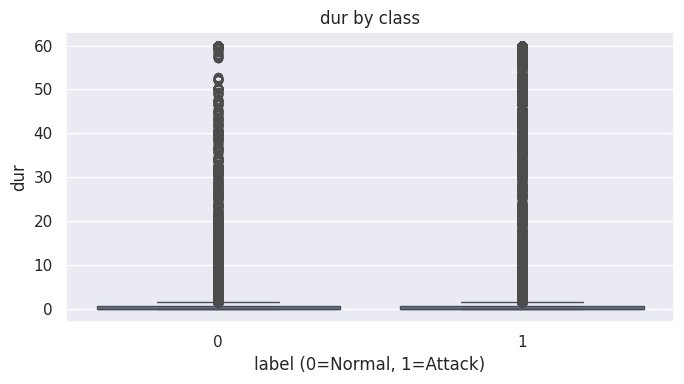

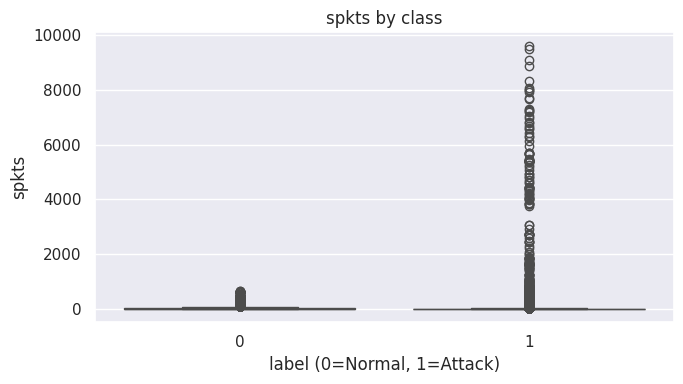

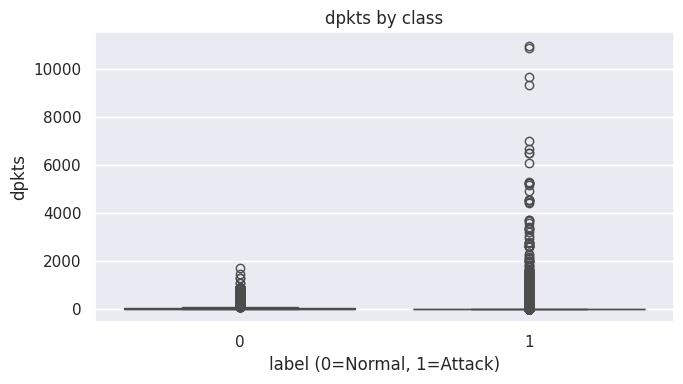

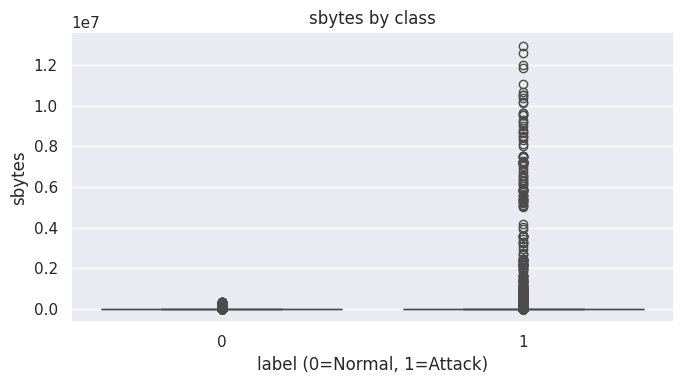

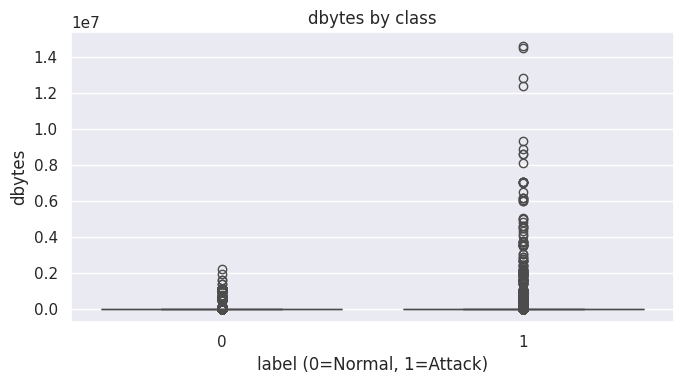

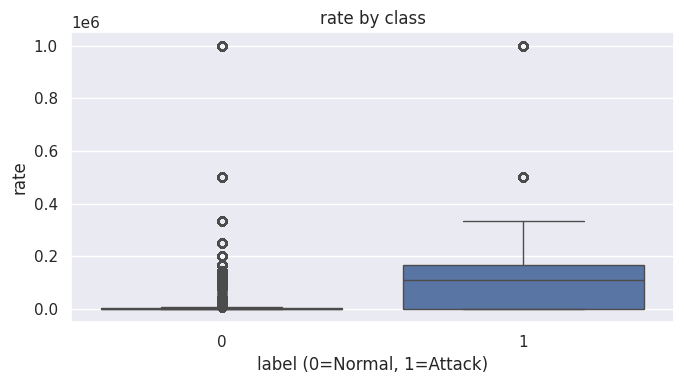

In [9]:
# Compare selected numeric features by label.
for feature in available_numeric[:6]:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=train_raw, x="label", y=feature)
    plt.title(f"{feature} by class")
    plt.xlabel("label (0=Normal, 1=Attack)")
    plt.tight_layout()
    plt.show()

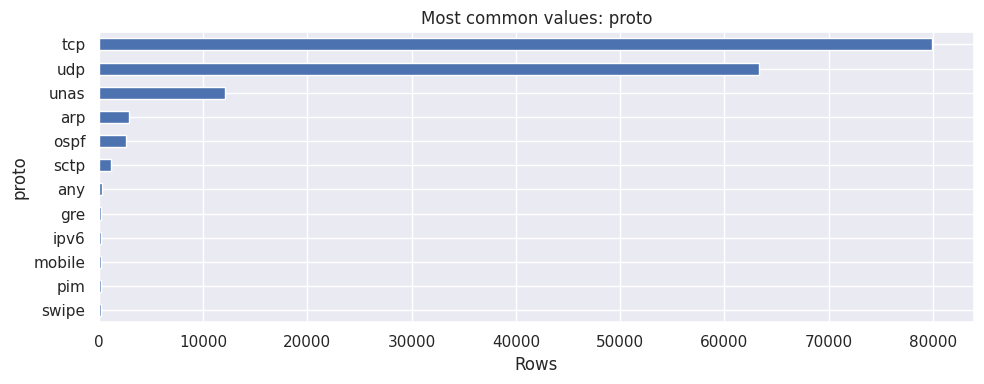

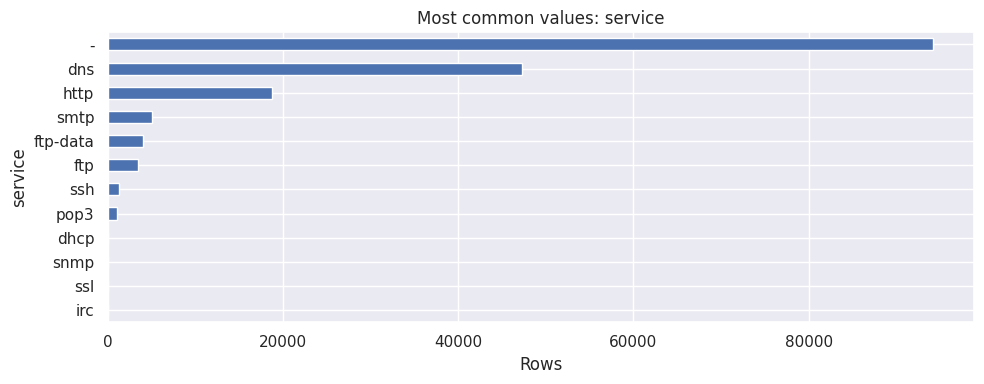

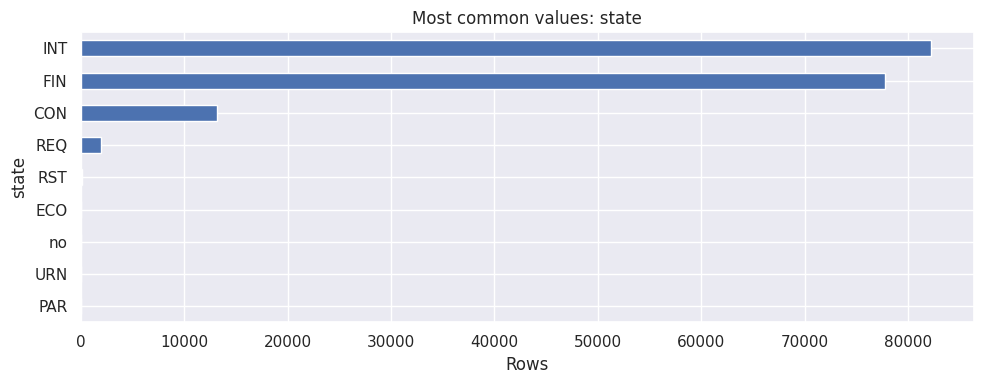

In [10]:
# Categorical features are encoded later. Here we inspect the most common categories.
candidate_categorical = ["proto", "service", "state"]
available_categorical = [c for c in candidate_categorical if c in train_raw.columns]

for feature in available_categorical:
    top_values = train_raw[feature].astype("string").value_counts().head(12)
    plt.figure(figsize=(10, 4))
    top_values.sort_values().plot(kind="barh")
    plt.title(f"Most common values: {feature}")
    plt.xlabel("Rows")
    plt.tight_layout()
    plt.show()

### 6.1 Correlation is a clue, not a feature-selection verdict

Pearson correlation measures linear relationships between numeric columns. We exclude identifiers and target columns from the feature correlation heatmap. High correlation may indicate redundancy, but it does not automatically mean one feature should be removed.

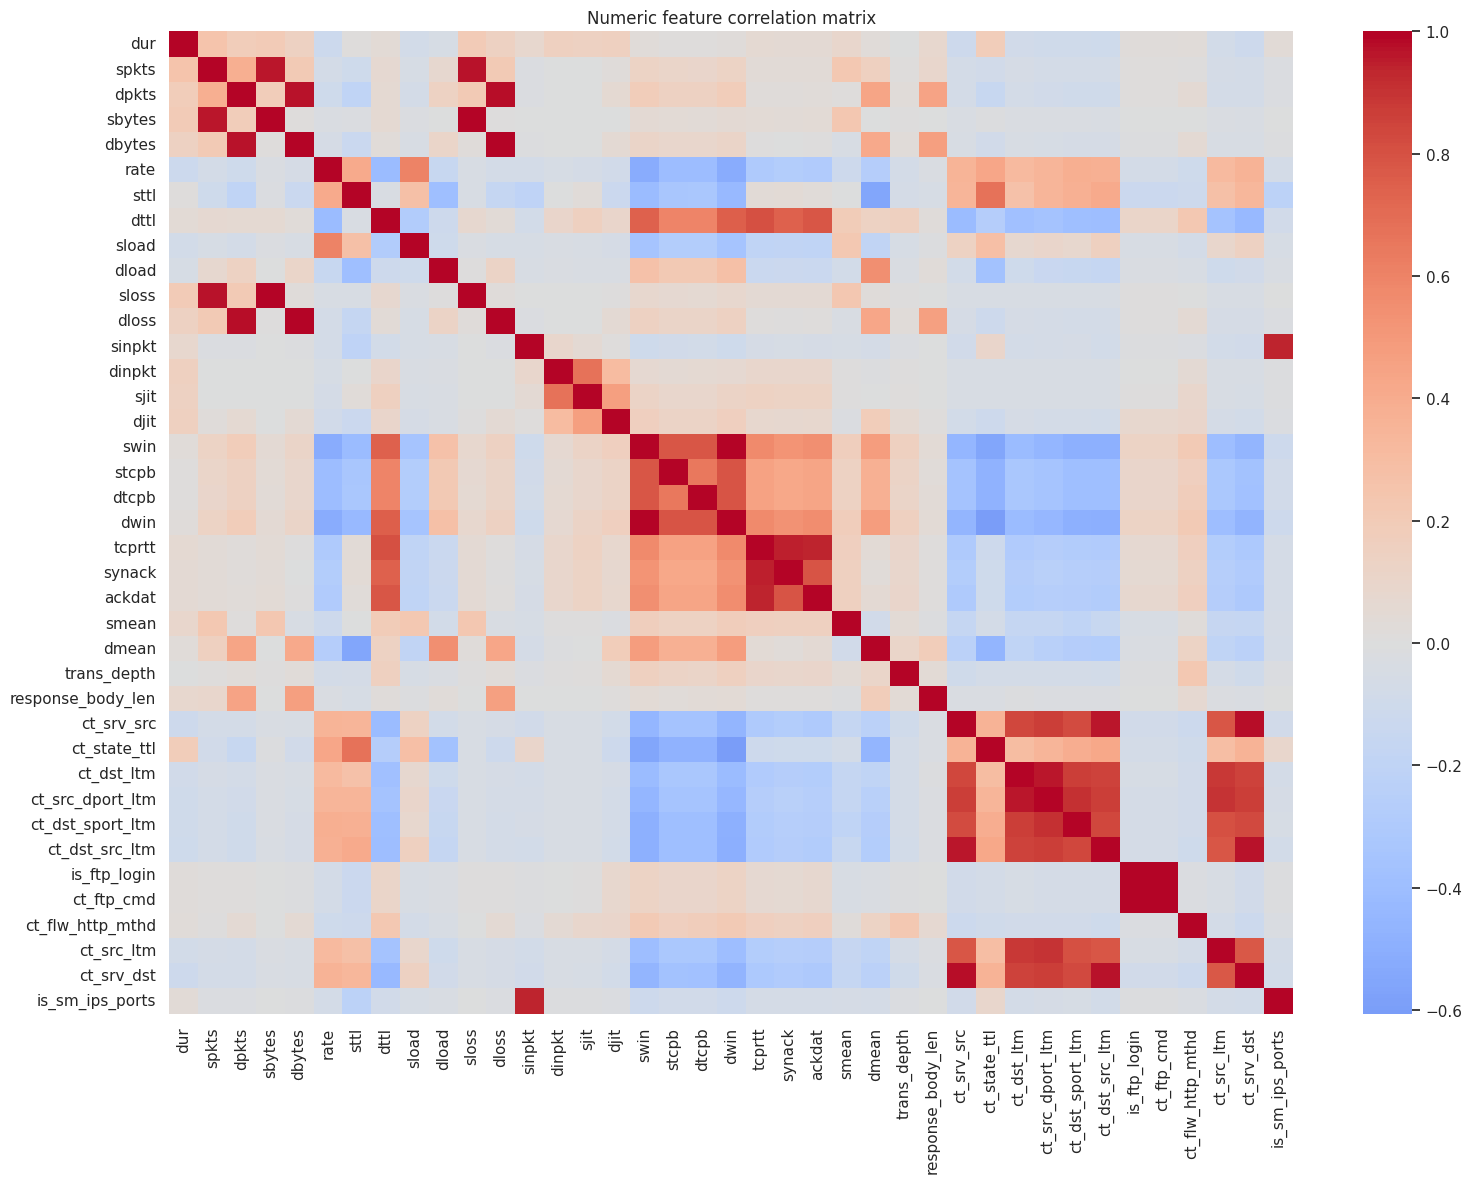

In [11]:
numeric_for_corr = train_raw.select_dtypes(include=np.number).columns.tolist()
numeric_for_corr = [c for c in numeric_for_corr if c not in ["id", "label"]]

if len(numeric_for_corr) > 1:
    corr = train_raw[numeric_for_corr].corr()
    plt.figure(figsize=(16, 12))
    sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=True, yticklabels=True)
    plt.title("Numeric feature correlation matrix")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric feature columns for a correlation matrix.")

## 7. Define features and prevent target leakage

For the standard UNSW-NB15 binary task:
- `label` is the target.
- `attack_cat` describes the attack category and must not be used to predict `label`, because it leaks target-related information.
- `id` is an identifier, not a traffic-behaviour feature, so we exclude it.

We also exclude any other target-derived or administrative columns if they exist. We keep `proto`, `service`, and `state` as categorical features when present.

This notebook intentionally uses the labelled training CSV for model development and the provided labelled test CSV only for final evaluation.

In [12]:
TARGET = "label"
DROP_FROM_FEATURES = ["id", "attack_cat", TARGET]

# Align the schema: use columns present in both files, excluding target-derived fields.
feature_columns = [
    c for c in train_raw.columns
    if c in test_raw.columns and c not in DROP_FROM_FEATURES
]

X_all = train_raw[feature_columns].copy()
y_all = train_raw[TARGET].astype(int).copy()

X_test = test_raw[feature_columns].copy()
y_test = test_raw[TARGET].astype(int).copy()

# Confirm binary target values.
assert set(y_all.unique()).issubset({0, 1}), "Expected binary target values 0 and 1."
assert set(y_test.unique()).issubset({0, 1}), "Expected binary target values 0 and 1."

print("Number of input features:", len(feature_columns))
print("Training matrix:", X_all.shape)
print("Final test matrix:", X_test.shape)
print("Dropped columns if present:", [c for c in DROP_FROM_FEATURES if c in train_raw.columns])

Number of input features: 42
Training matrix: (175341, 42)
Final test matrix: (82332, 42)
Dropped columns if present: ['id', 'attack_cat', 'label']


## 8. Train/validation split

We split only the provided training file into:
- `X_train`, `y_train`: fit candidate models.
- `X_valid`, `y_valid`: compare models and choose settings/thresholds.

`stratify=y_all` keeps the class proportions approximately similar in both subsets. The separate provided test file remains untouched until the final evaluation section.

In [13]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X_all,
    y_all,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_all
)

print("Development training:", X_train.shape)
print("Validation:", X_valid.shape)
print("Reserved final test:", X_test.shape)

print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("Validation class proportions:")
display(y_valid.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Development training: (140272, 42)
Validation: (35069, 42)
Reserved final test: (82332, 42)

Training class proportions:


,proportion
label,
0,0.319379
1,0.680621


Validation class proportions:


,proportion
label,
0,0.31937
1,0.68063


## 9. Build preprocessing safely

The input includes numeric and categorical columns. Most scikit-learn models require numeric arrays, so:
- Numeric values: fill missing values with the median, then standardize.
- Categorical values: fill missing values with the most frequent value, then one-hot encode.
- Unknown categories at validation/test time are ignored by the encoder.

We create the transformer using columns discovered from the actual dataset. The preprocessing is part of each model's `Pipeline`, so it is fitted only on the training data (and separately inside cross-validation folds).

In [14]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Categorical column names:", categorical_features)

Numeric features: 39
Categorical features: 3
Categorical column names: ['proto', 'service', 'state']


## 10. Define evaluation metrics

For attack detection, treat class `1` (Attack) as the positive class:
- **Precision:** Of the records flagged as attacks, how many were attacks?
- **Recall:** Of all actual attacks, how many did the model catch?
- **F1-score:** Harmonic mean of precision and recall.
- **False-positive rate (FPR):** Of all normal records, how many were incorrectly flagged?
- **ROC-AUC:** Ranking quality across thresholds.
- **PR-AUC / Average Precision:** Precision-recall performance, especially useful when class balance is uneven.

A security team may prefer higher recall to miss fewer attacks, but high recall can create more false alarms. We should report both.

In [15]:
def calculate_metrics(y_true, y_pred, y_score=None):
    """Return a compact set of binary-classification metrics; class 1 means Attack."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    results = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_attack": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall_attack": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1_attack": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "false_positive_rate": fp / (fp + tn) if (fp + tn) else 0.0,
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp)
    }

    if y_score is not None:
        results["roc_auc"] = roc_auc_score(y_true, y_score)
        results["average_precision"] = average_precision_score(y_true, y_score)

    return results


def get_attack_scores(fitted_pipeline, X):
    """Return class-1 probabilities when available, otherwise decision scores."""
    model = fitted_pipeline.named_steps["model"]
    if hasattr(fitted_pipeline, "predict_proba"):
        return fitted_pipeline.predict_proba(X)[:, 1]
    if hasattr(fitted_pipeline, "decision_function"):
        return fitted_pipeline.decision_function(X)
    return None

## 11. Baseline: DummyClassifier

Before complex models, we need a simple reference. `DummyClassifier` ignores feature patterns and predicts using a simple rule. If a real model cannot beat a simple baseline on meaningful metrics, that is a warning sign.

In [16]:
dummy_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", DummyClassifier(strategy="prior"))
])

dummy_pipeline.fit(X_train, y_train)
dummy_pred = dummy_pipeline.predict(X_valid)
dummy_score = get_attack_scores(dummy_pipeline, X_valid)
dummy_metrics = calculate_metrics(y_valid, dummy_pred, dummy_score)

display(pd.DataFrame([{"model": "DummyClassifier", **dummy_metrics}]).round(4))

,model,accuracy,precision_attack,recall_attack,f1_attack,false_positive_rate,true_negatives,false_positives,false_negatives,true_positives,roc_auc,average_precision
0,DummyClassifier,0.6806,0.6806,1.0,0.81,1.0,0,11200,0,23869,0.5,0.6806


## 12. Train candidate models

We compare several different modelling ideas:
- **Logistic Regression:** A relatively simple linear baseline; coefficients can be inspected, though one-hot encoded features make interpretation more involved.
- **Decision Tree:** Learns rule-like splits and is easy to explain, but a single tree can overfit.
- **Random Forest:** A collection of decision trees trained with randomness; averages their predictions to improve robustness.
- **Extra Trees:** Similar to Random Forest, but uses more randomized split choices.

All models use the same preprocessing pipeline. Tree ensembles can be more computationally expensive, so adjust the number of trees if Kaggle runtime is limited.

In [17]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=18,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=150,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
}

fitted_models = {}
validation_predictions = {}
validation_scores = {}
metric_rows = [{"model": "DummyClassifier", **dummy_metrics}]

for model_name, estimator in models.items():
    print(f"Training: {model_name}")
    pipeline = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", estimator)
    ])
    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_valid)
    scores = get_attack_scores(pipeline, X_valid)
    metrics = calculate_metrics(y_valid, predictions, scores)

    fitted_models[model_name] = pipeline
    validation_predictions[model_name] = predictions
    validation_scores[model_name] = scores
    metric_rows.append({"model": model_name, **metrics})

validation_results = pd.DataFrame(metric_rows).set_index("model")
display(validation_results.round(4).sort_values("f1_attack", ascending=False))

Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: Extra Trees


,accuracy,precision_attack,recall_attack,f1_attack,false_positive_rate,true_negatives,false_positives,false_negatives,true_positives,roc_auc,average_precision
model,,,,,,,,,,,
Random Forest,0.9582,0.9700,0.9685,0.9692,0.0639,10484,716,751,23118,0.9938,0.9971
Extra Trees,0.9529,0.9688,0.9618,0.9653,0.0660,10461,739,912,22957,0.9923,0.9963
Decision Tree,0.9416,0.9778,0.9355,0.9562,0.0454,10692,508,1539,22330,0.9811,0.9853
Logistic Regression,0.9326,0.9503,0.9507,0.9505,0.1060,10013,1187,1177,22692,0.9845,0.9919
DummyClassifier,0.6806,0.6806,1.0000,0.8100,1.0000,0,11200,0,23869,0.5000,0.6806


## 13. Compare models visually

No single metric tells the whole story. We compare F1 and recall for attacks, alongside false-positive rate. High attack recall is useful, but a model with too many false positives may overwhelm analysts.

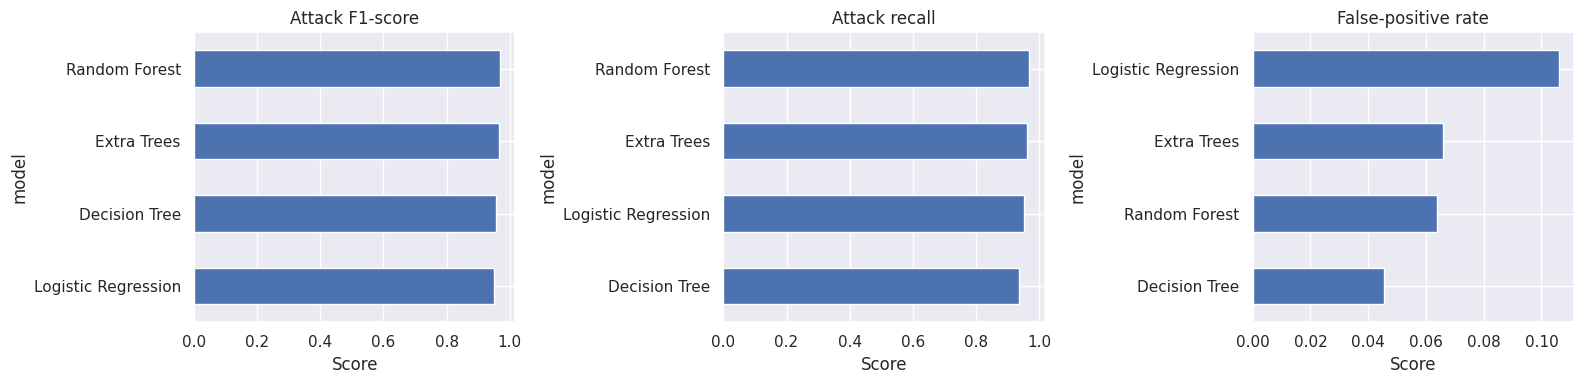

In [18]:
plot_metrics = validation_results.drop(index="DummyClassifier", errors="ignore")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
plot_metrics["f1_attack"].sort_values().plot(kind="barh", ax=axes[0], title="Attack F1-score")
plot_metrics["recall_attack"].sort_values().plot(kind="barh", ax=axes[1], title="Attack recall")
plot_metrics["false_positive_rate"].sort_values().plot(kind="barh", ax=axes[2], title="False-positive rate")
for ax in axes:
    ax.set_xlabel("Score")
plt.tight_layout()
plt.show()

### 13.1 Confusion matrices and classification reports

Confusion matrix layout for labels `[0, 1]`:
- Top-left: True Normal (TN)
- Top-right: Normal incorrectly flagged as Attack (FP)
- Bottom-left: Attack missed as Normal (FN)
- Bottom-right: Attack correctly detected (TP)


Logistic Regression
              precision    recall  f1-score   support

  Normal (0)       0.89      0.89      0.89     11200
  Attack (1)       0.95      0.95      0.95     23869

    accuracy                           0.93     35069
   macro avg       0.92      0.92      0.92     35069
weighted avg       0.93      0.93      0.93     35069



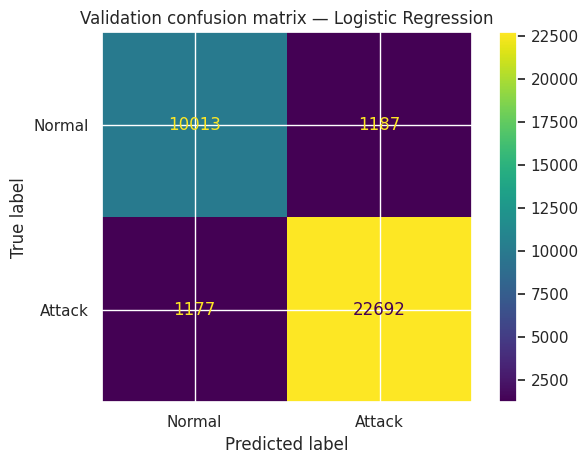


Decision Tree
              precision    recall  f1-score   support

  Normal (0)       0.87      0.95      0.91     11200
  Attack (1)       0.98      0.94      0.96     23869

    accuracy                           0.94     35069
   macro avg       0.93      0.95      0.93     35069
weighted avg       0.94      0.94      0.94     35069



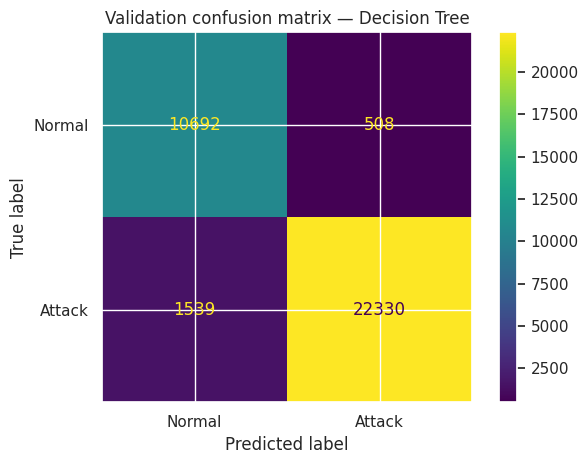


Random Forest
              precision    recall  f1-score   support

  Normal (0)       0.93      0.94      0.93     11200
  Attack (1)       0.97      0.97      0.97     23869

    accuracy                           0.96     35069
   macro avg       0.95      0.95      0.95     35069
weighted avg       0.96      0.96      0.96     35069



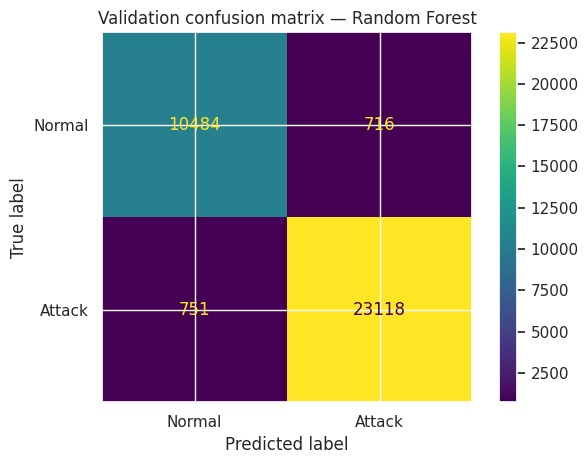


Extra Trees
              precision    recall  f1-score   support

  Normal (0)       0.92      0.93      0.93     11200
  Attack (1)       0.97      0.96      0.97     23869

    accuracy                           0.95     35069
   macro avg       0.94      0.95      0.95     35069
weighted avg       0.95      0.95      0.95     35069



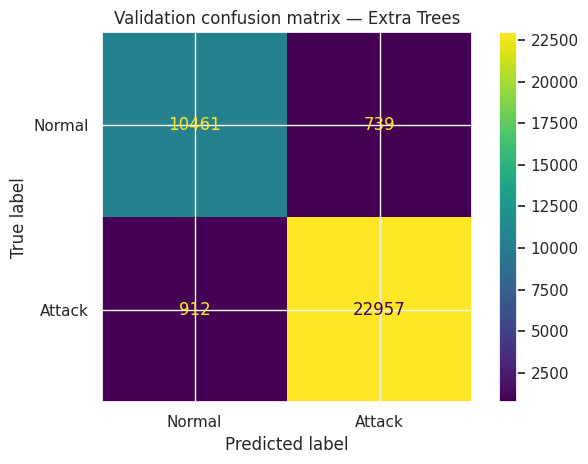

In [19]:
for model_name, predictions in validation_predictions.items():
    print("\n" + "=" * 70)
    print(model_name)
    print(classification_report(
        y_valid, predictions,
        labels=[0, 1],
        target_names=["Normal (0)", "Attack (1)"],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_valid, predictions,
        labels=[0, 1],
        display_labels=["Normal", "Attack"],
        values_format="d"
    )
    plt.title(f"Validation confusion matrix — {model_name}")
    plt.tight_layout()
    plt.show()

### 13.2 ROC and precision-recall curves

Curves use model scores, not only hard class predictions. ROC-AUC shows ranking performance over many thresholds. The precision-recall curve makes the precision/recall trade-off explicit.

These curves are computed on validation data for model comparison only.

<Figure size 700x600 with 0 Axes>

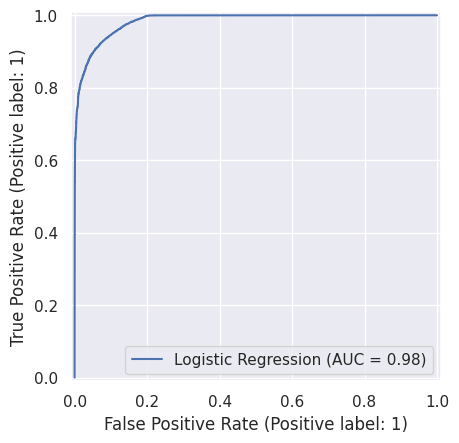

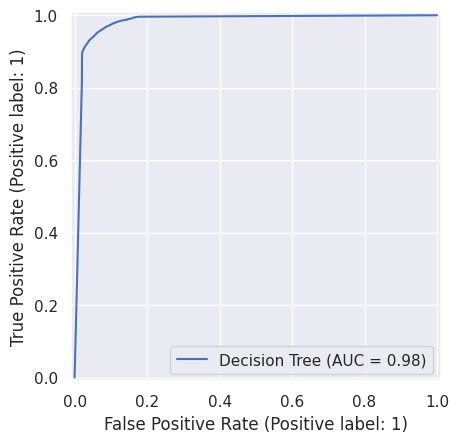

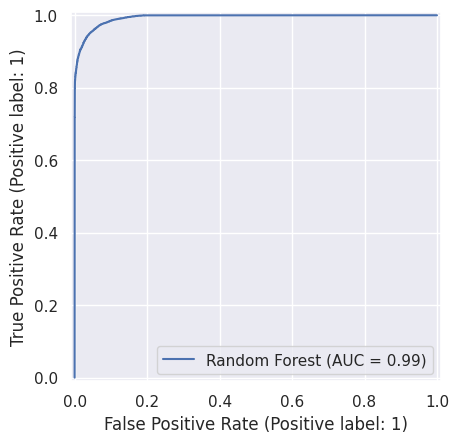

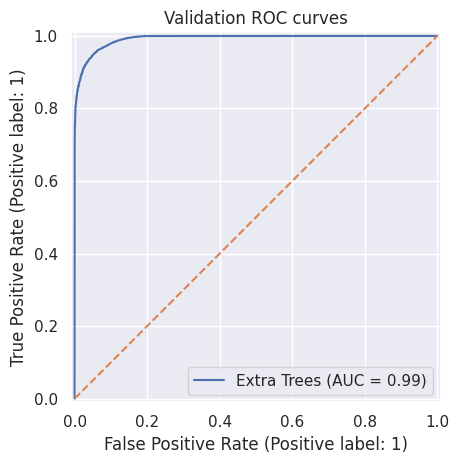

<Figure size 700x600 with 0 Axes>

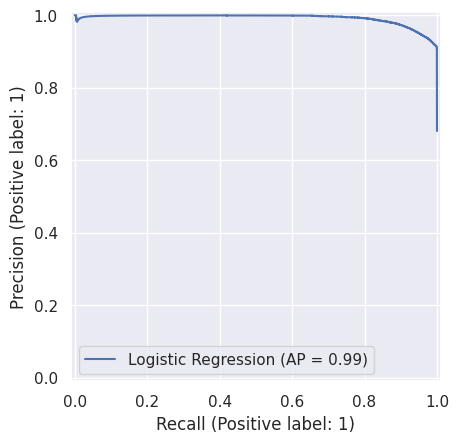

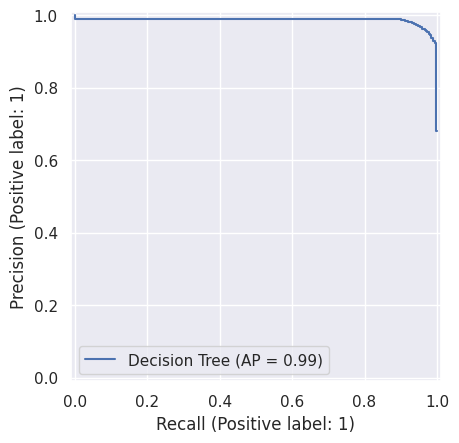

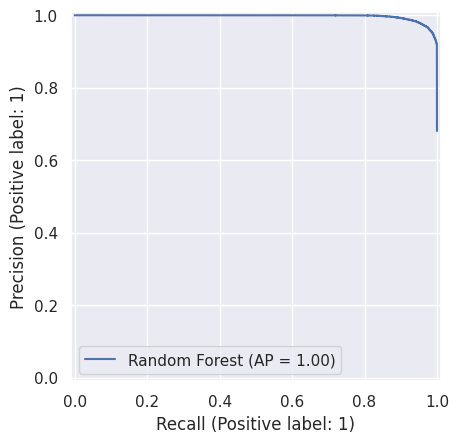

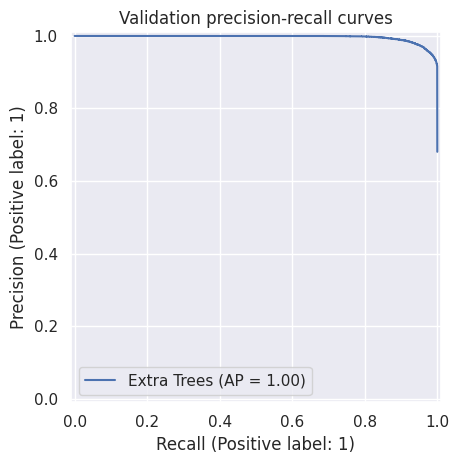

In [20]:
plt.figure(figsize=(7, 6))
for model_name, scores in validation_scores.items():
    if scores is not None:
        RocCurveDisplay.from_predictions(y_valid, scores, name=model_name)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
plt.title("Validation ROC curves")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
for model_name, scores in validation_scores.items():
    if scores is not None:
        PrecisionRecallDisplay.from_predictions(y_valid, scores, name=model_name)
plt.title("Validation precision-recall curves")
plt.tight_layout()
plt.show()

## 14. Choose a model using validation results

For this learning project, we select the model with the highest validation attack F1-score as a transparent default. In a real IDS, the decision should reflect the cost of missed attacks, false alarms, latency, and operational constraints.

This choice is made using validation data, not the final test set.

In [21]:
# Remove the dummy baseline when choosing the production candidate.
candidate_results = validation_results.drop(index="DummyClassifier", errors="ignore")
selected_model_name = candidate_results["f1_attack"].idxmax()
selected_pipeline = fitted_models[selected_model_name]

print("Selected model based on validation attack F1:", selected_model_name)
display(candidate_results.loc[[selected_model_name]].round(4))

Selected model based on validation attack F1: Random Forest


,accuracy,precision_attack,recall_attack,f1_attack,false_positive_rate,true_negatives,false_positives,false_negatives,true_positives,roc_auc,average_precision
model,,,,,,,,,,,
Random Forest,0.9582,0.97,0.9685,0.9692,0.0639,10484,716,751,23118,0.9938,0.9971


## 15. Hyperparameter tuning with cross-validation

Hyperparameters are settings chosen before/during training, such as tree depth and number of trees. `RandomizedSearchCV` tries a limited number of combinations and evaluates them using stratified cross-validation.

**Runtime note:** This can be expensive. Start with a small search. If needed, set `SEARCH_ITERATIONS = 5` or use a stratified subset of the training data for experimentation. Do not use the final test set for tuning.

In [22]:
SEARCH_ITERATIONS = 8
CV_FOLDS = 3

# Keep the search space modest for Kaggle runtime. We tune a Random Forest pipeline.
rf_search_pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

rf_param_distributions = {
    "model__n_estimators": [100, 150, 250],
    "model__max_depth": [None, 12, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", 0.5]
}

cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)

rf_search = RandomizedSearchCV(
    estimator=rf_search_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=SEARCH_ITERATIONS,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    random_state=RANDOM_STATE,
    refit=True
)

rf_search.fit(X_train, y_train)

print("Best CV F1:", round(rf_search.best_score_, 4))
print("Best parameters:")
display(pd.Series(rf_search.best_params_, name="value").to_frame())

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best CV F1: 0.9684
Best parameters:


,value
model__n_estimators,100.0
model__min_samples_split,5.0
model__min_samples_leaf,2.0
model__max_features,0.5
model__max_depth,30.0


### 15.1 Evaluate the tuned model on validation data

The best cross-validation model is evaluated on validation data. We compare it with the earlier model candidates before making the final model choice.

In [23]:
tuned_pipeline = rf_search.best_estimator_
tuned_valid_pred = tuned_pipeline.predict(X_valid)
tuned_valid_score = get_attack_scores(tuned_pipeline, X_valid)
tuned_valid_metrics = calculate_metrics(y_valid, tuned_valid_pred, tuned_valid_score)

comparison_after_tuning = pd.concat([
    validation_results,
    pd.DataFrame([tuned_valid_metrics], index=["Tuned Random Forest"])
])
display(comparison_after_tuning.round(4).sort_values("f1_attack", ascending=False))

,accuracy,precision_attack,recall_attack,f1_attack,false_positive_rate,true_negatives,false_positives,false_negatives,true_positives,roc_auc,average_precision
Tuned Random Forest,0.9609,0.9705,0.9721,0.9713,0.0630,10494,706,665,23204,0.9940,0.9970
Random Forest,0.9582,0.9700,0.9685,0.9692,0.0639,10484,716,751,23118,0.9938,0.9971
Extra Trees,0.9529,0.9688,0.9618,0.9653,0.0660,10461,739,912,22957,0.9923,0.9963
Decision Tree,0.9416,0.9778,0.9355,0.9562,0.0454,10692,508,1539,22330,0.9811,0.9853
Logistic Regression,0.9326,0.9503,0.9507,0.9505,0.1060,10013,1187,1177,22692,0.9845,0.9919
DummyClassifier,0.6806,0.6806,1.0000,0.8100,1.0000,0,11200,0,23869,0.5000,0.6806


## 16. Threshold analysis

Many classifiers output a score or probability. The default class decision often uses a threshold of 0.5, but that is not always the best operational choice.

- Lower threshold: usually catches more attacks (higher recall), but may increase false alarms.
- Higher threshold: usually reduces false alarms, but may miss more attacks.

We select a threshold using **validation scores only**. This code requires probability scores in the range 0–1; Random Forest provides them.

In [24]:
# Use the tuned Random Forest for threshold analysis.
threshold_model = tuned_pipeline
threshold_scores = threshold_model.predict_proba(X_valid)[:, 1]

threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.05):
    threshold_pred = (threshold_scores >= threshold).astype(int)
    metrics = calculate_metrics(y_valid, threshold_pred)
    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "precision_attack": metrics["precision_attack"],
        "recall_attack": metrics["recall_attack"],
        "f1_attack": metrics["f1_attack"],
        "false_positive_rate": metrics["false_positive_rate"],
        "false_negatives": metrics["false_negatives"],
        "false_positives": metrics["false_positives"]
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(4))

,threshold,precision_attack,recall_attack,f1_attack,false_positive_rate,false_negatives,false_positives
0,0.10,0.9211,0.9993,0.9586,0.1825,16,2044
1,0.15,0.9264,0.9982,0.9609,0.1690,44,1893
2,0.20,0.9330,0.9963,0.9636,0.1525,89,1708
3,0.25,0.9400,0.9937,0.9661,0.1351,151,1513
4,0.30,0.9467,0.9914,0.9686,0.1188,205,1331
5,0.35,0.9539,0.9877,0.9705,0.1017,294,1139
6,0.40,0.9593,0.9835,0.9712,0.0890,395,997
7,0.45,0.9652,0.9783,0.9717,0.0753,519,843
8,0.50,0.9705,0.9721,0.9713,0.0630,665,706
9,0.55,0.9751,0.9651,0.9701,0.0525,834,588


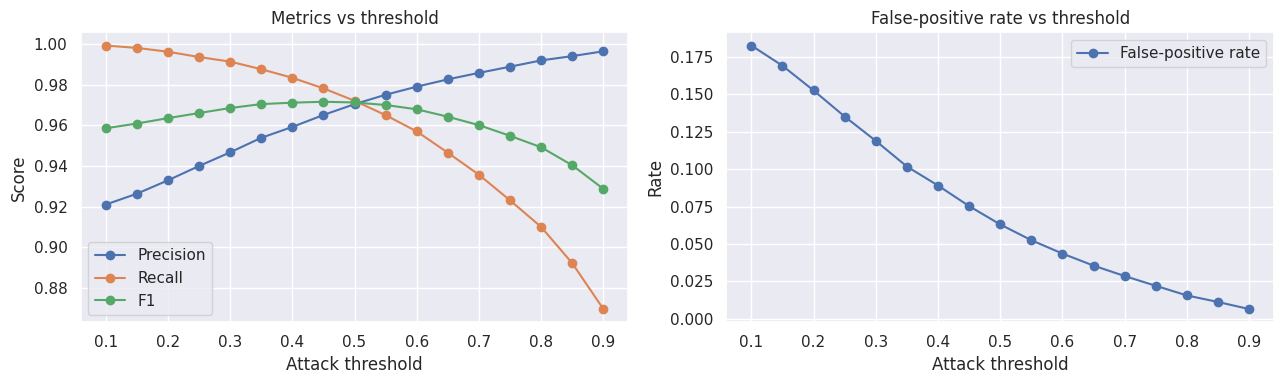

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(threshold_results["threshold"], threshold_results["precision_attack"], marker="o", label="Precision")
axes[0].plot(threshold_results["threshold"], threshold_results["recall_attack"], marker="o", label="Recall")
axes[0].plot(threshold_results["threshold"], threshold_results["f1_attack"], marker="o", label="F1")
axes[0].set_title("Metrics vs threshold")
axes[0].set_xlabel("Attack threshold")
axes[0].set_ylabel("Score")
axes[0].legend()

axes[1].plot(threshold_results["threshold"], threshold_results["false_positive_rate"], marker="o", label="False-positive rate")
axes[1].set_title("False-positive rate vs threshold")
axes[1].set_xlabel("Attack threshold")
axes[1].set_ylabel("Rate")
axes[1].legend()

plt.tight_layout()
plt.show()

### 16.1 Choose an operating threshold

Here we choose the threshold with the best validation F1-score as a simple demonstration. For a real deployment, a threshold might instead be selected to meet a required minimum recall or maximum false-positive rate. Write down the criterion you use.

In [26]:
best_threshold_row = threshold_results.loc[threshold_results["f1_attack"].idxmax()]
SELECTED_THRESHOLD = float(best_threshold_row["threshold"])

print("Selected threshold based on validation F1:", SELECTED_THRESHOLD)
display(best_threshold_row.to_frame("value"))

Selected threshold based on validation F1: 0.45


,value
threshold,0.450000
precision_attack,0.965155
recall_attack,0.978256
f1_attack,0.971662
false_positive_rate,0.075268
false_negatives,519.000000
false_positives,843.000000


## 17. Explainability with permutation importance

Permutation importance measures how much a metric degrades when a feature's values are shuffled. If shuffling a feature reduces F1 substantially, the fitted model relies on information associated with that feature.

This is model-agnostic and can be easier to explain than raw coefficients. It can be computationally expensive, so we use a validation sample. Importance indicates predictive reliance, not causation.

,feature,importance_mean,importance_std
9,sttl,0.23093,0.00557
26,smean,0.00773,0.00061
40,ct_srv_dst,0.00747,0.00075
6,sbytes,0.00671,0.00131
24,synack,0.00540,0.00042
30,ct_srv_src,0.00427,0.00110
27,dmean,0.00388,0.00095
35,ct_dst_src_ltm,0.00305,0.00102
7,dbytes,0.00286,0.00085
16,dinpkt,0.00286,0.00032


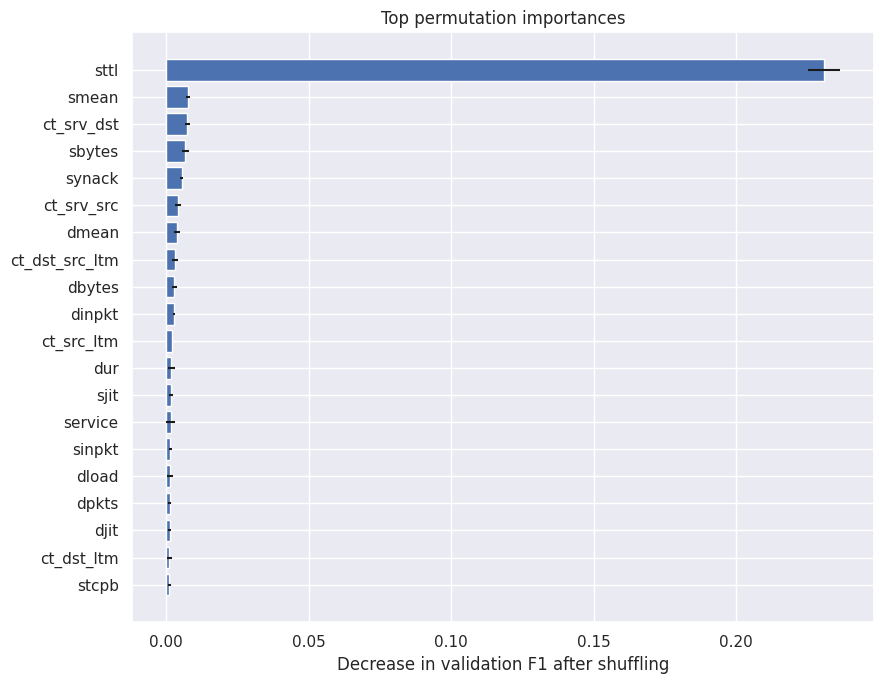

In [27]:
# Use a bounded sample to keep permutation importance manageable.
IMPORTANCE_SAMPLE_SIZE = min(3000, len(X_valid))
X_importance = X_valid.sample(
    n=IMPORTANCE_SAMPLE_SIZE,
    random_state=RANDOM_STATE
)
y_importance = y_valid.loc[X_importance.index]

importance = permutation_importance(
    tuned_pipeline,
    X_importance,
    y_importance,
    scoring="f1",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_importance.columns,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_df.head(20).round(5))

top_importance = importance_df.head(20).sort_values("importance_mean")
plt.figure(figsize=(9, 7))
plt.barh(top_importance["feature"], top_importance["importance_mean"], xerr=top_importance["importance_std"])
plt.xlabel("Decrease in validation F1 after shuffling")
plt.title("Top permutation importances")
plt.tight_layout()
plt.show()

### 17.1 Optional SHAP explanation

SHAP is optional because it may need installation and can be computationally heavy. For tree-based models, `TreeExplainer` can explain a small sample of transformed features, but preprocessing and one-hot encoded feature names make this more involved.

Run this section only after the core pipeline works. SHAP values explain model output under the explainer's assumptions; they do not prove causality.

In [28]:
# Optional: uncomment and run if SHAP is needed in this Kaggle session.
# !pip -q install shap
#
# import shap
#
# # Explain a small sample to control runtime.
# X_shap = X_valid.sample(n=min(200, len(X_valid)), random_state=RANDOM_STATE)
# fitted_preprocessor = tuned_pipeline.named_steps["preprocess"]
# transformed_shap = fitted_preprocessor.transform(X_shap)
# tree_model = tuned_pipeline.named_steps["model"]
#
# # For sparse output, convert only this small sample to dense.
# if hasattr(transformed_shap, "toarray"):
#     transformed_shap = transformed_shap.toarray()
#
# feature_names = fitted_preprocessor.get_feature_names_out()
# explainer = shap.TreeExplainer(tree_model)
# shap_values = explainer.shap_values(transformed_shap)
# print("SHAP values calculated. Inspect the SHAP documentation for the output format")
# print("of the installed SHAP version before plotting.")

## 18. Inspect validation errors

Error analysis helps us understand what the model misses. We look at:
- False negatives: actual attacks predicted as normal.
- False positives: normal traffic predicted as attacks.

These examples can reveal patterns worth investigating. Do not assume that the model is wrong in every case; labels and features can themselves be imperfect.

In [29]:
error_predictions = (threshold_scores >= SELECTED_THRESHOLD).astype(int)

validation_errors = X_valid.copy()
validation_errors["actual_label"] = y_valid
validation_errors["predicted_label"] = error_predictions
validation_errors["attack_score"] = threshold_scores

false_negatives = validation_errors[
    (validation_errors["actual_label"] == 1) &
    (validation_errors["predicted_label"] == 0)
]
false_positives = validation_errors[
    (validation_errors["actual_label"] == 0) &
    (validation_errors["predicted_label"] == 1)
]

print("False negatives (missed attacks):", len(false_negatives))
print("False positives (normal flagged as attack):", len(false_positives))

print("\nExample false negatives:")
display(false_negatives.head(10))

print("\nExample false positives:")
display(false_positives.head(10))

False negatives (missed attacks): 519
False positives (normal flagged as attack): 843

Example false negatives:


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,actual_label,predicted_label,attack_score
60775,0.710725,tcp,ftp,FIN,12,12,632,682,32.361321,254,252,6.528545e+03,7046.325684,3,4,64.611366,55.870273,3486.044172,87.914492,255,2001683627,2612990589,255,0.144800,0.076857,0.067943,53,57,0,0,2,1,1,1,1,2,0,0,0,1,2,0,1,0,0.216053
69020,0.434947,tcp,-,FIN,10,6,502,268,34.486959,254,252,8.313656e+03,4120.041992,2,1,48.223556,75.322000,2321.040675,107.653039,255,2851580771,877880177,255,0.118473,0.058336,0.060137,50,45,0,0,9,1,2,2,1,8,0,0,0,3,8,0,1,0,0.360187
124624,0.770439,tcp,http,FIN,10,8,858,1094,22.065341,62,252,8.026592e+03,9947.575195,2,2,85.604333,100.749289,4643.976605,180.463984,255,2741837122,660202105,255,0.210179,0.064420,0.145759,86,137,1,126,2,1,1,1,1,2,0,0,1,1,2,0,1,0,0.254433
98492,0.000004,udp,-,INT,2,0,1064,0,250000.000600,254,0,1.064000e+09,0.000000,0,0,0.004000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,532,0,0,0,3,2,1,1,1,1,0,0,0,3,1,0,1,0,0.383951
124987,0.712601,tcp,-,FIN,10,6,534,268,21.049648,254,252,5.399936e+03,2514.731201,2,1,79.064444,122.737000,4080.464629,211.607172,255,2135415522,559120556,255,0.179254,0.098915,0.080339,53,45,0,0,4,1,1,1,1,2,0,0,0,5,2,0,1,0,0.224184
48633,0.000010,udp,-,INT,2,0,104,0,100000.002500,254,0,4.160000e+07,0.000000,0,0,0.010000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,52,0,0,0,2,2,1,1,1,2,0,0,0,1,3,0,1,0,0.432291
64331,0.639265,tcp,-,FIN,10,8,654,354,26.593040,254,252,7.370965e+03,3879.455322,2,1,64.988778,78.341289,3747.828510,137.966594,255,2129823388,779875058,255,0.139485,0.090867,0.048618,65,44,0,0,3,1,1,1,1,3,0,0,0,1,4,0,1,0,0.380764
84888,1.390644,tcp,ftp,FIN,64,20,68216,1026,59.684580,254,252,3.863016e+05,5608.912109,29,4,21.721365,70.030578,2025.588717,89.511258,255,1407373081,345613481,255,0.141785,0.060059,0.081726,1066,51,0,0,3,1,1,1,1,3,1,1,0,1,3,0,1,0,0.157854
48589,0.645488,tcp,-,FIN,10,8,534,354,26.336662,254,252,5.961381e+03,3842.054199,2,1,69.539778,82.916430,3941.676781,165.225109,255,415662920,2520566766,255,0.113426,0.065065,0.048361,53,44,0,0,4,1,1,1,1,4,0,0,0,1,4,0,1,0,0.200484
101940,0.750977,tcp,-,FIN,34,12,28612,642,59.921943,254,252,2.958386e+05,6274.493164,14,3,22.182606,61.350816,1642.614945,82.831602,255,1750349835,2527545798,255,0.170577,0.076115,0.094462,842,54,0,0,6,1,1,1,1,5,0,0,0,1,5,0,1,0,0.184195



Example false positives:


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,actual_label,predicted_label,attack_score
44768,0.912222,tcp,http,FIN,10,10,872,1182,20.828263,62,252,6.884289e+03,9331.061523,2,2,101.297333,91.382000,6007.205631,164.110891,255,2048318757,998816593,255,0.193962,0.089779,0.104183,87,118,0,0,1,1,1,1,1,1,0,0,0,19,1,0,0,1,0.470503
71295,0.341294,tcp,-,FIN,20,8,17266,354,79.110681,254,252,3.844896e+05,7266.462402,7,1,16.872316,40.049570,1295.602356,71.538516,255,3575840955,3011741822,255,0.115786,0.060938,0.054848,863,44,0,0,11,1,3,3,1,10,0,0,0,3,10,0,0,1,0.557776
104719,0.836262,tcp,-,FIN,10,8,534,354,20.328558,254,252,4.601429e+03,2965.577881,2,1,92.918000,109.422859,5309.078014,238.693234,255,3889260339,3563178687,255,0.095707,0.069541,0.026166,53,44,0,0,2,1,1,1,1,2,0,0,0,1,2,0,0,1,0.651834
43950,1.220380,tcp,-,FIN,14,8,5154,754,17.207756,254,252,3.137384e+04,4326.521484,4,2,90.266385,160.150000,5083.404630,221.894266,255,3838598773,3733473280,255,0.213904,0.099329,0.114575,368,94,0,0,3,1,3,1,1,2,0,0,0,2,3,0,0,1,0.949970
45603,0.000010,udp,-,INT,2,0,104,0,100000.002500,254,0,4.160000e+07,0.000000,0,0,0.010000,0.000000,0.000000,0.000000,0,0,0,0,0.000000,0.000000,0.000000,52,0,0,0,1,2,1,1,1,1,0,0,0,1,1,0,0,1,0.605226
47223,1.445159,tcp,-,FIN,60,14,68043,612,50.513474,254,252,3.703897e+05,3149.826416,27,1,23.564170,101.235156,2261.877116,128.898687,255,3432482295,82573160,255,0.219735,0.129101,0.090634,1134,44,0,0,3,1,1,1,1,2,0,0,0,1,2,0,0,1,0.517179
41153,0.918903,tcp,-,FIN,10,8,622,354,18.500321,254,252,4.875378e+03,2698.870361,2,1,101.957889,123.933289,5997.058649,195.139938,255,696776111,1531200275,255,0.123221,0.051361,0.071860,62,44,0,0,2,1,1,1,1,1,0,0,0,1,1,0,0,1,0.968813
41448,0.714507,tcp,-,FIN,10,8,588,354,23.792630,254,252,5.934162e+03,3470.924805,2,1,74.545222,87.069430,4204.249529,150.564594,255,2582652836,2734651011,255,0.155621,0.105020,0.050601,59,44,0,0,2,1,1,1,1,2,0,0,0,2,2,0,0,1,0.475286
46805,0.717584,tcp,http,FIN,60,14,68199,612,101.730248,254,252,7.476532e+05,6343.508301,27,1,11.887542,52.639922,1247.430242,70.044227,255,833629558,1007384256,255,0.057342,0.033256,0.024086,1137,44,1,0,3,1,1,1,1,26,0,0,1,1,4,0,0,1,0.529729
41894,0.671723,tcp,http,FIN,12,8,1302,1022,28.285469,62,252,1.422015e+04,10659.155270,3,2,56.709817,80.345289,2874.992991,108.919711,255,1341624194,3373535596,255,0.195863,0.109300,0.086563,109,128,1,109,1,1,1,1,1,1,0,0,1,1,1,0,0,1,1.000000


## 19. Final evaluation on the reserved test set

Only after model selection and threshold selection are finished do we evaluate on the provided test file.

We compare the tuned Random Forest at its default threshold and at the validation-selected threshold. The threshold was selected without using test labels. These test results are the final holdout estimate for this workflow.

,accuracy,precision_attack,recall_attack,f1_attack,false_positive_rate,true_negatives,false_positives,false_negatives,true_positives,roc_auc,average_precision
setting,,,,,,,,,,,
"Tuned RF, threshold 0.50",0.8824,0.8330,0.9835,0.9020,0.2416,28061,8939,747,44585,0.982,0.9858
"Tuned RF, threshold 0.45",0.8719,0.8171,0.9887,0.8948,0.2712,26966,10034,510,44822,0.982,0.9858



Classification report at selected threshold:
              precision    recall  f1-score   support

  Normal (0)       0.98      0.73      0.84     37000
  Attack (1)       0.82      0.99      0.89     45332

    accuracy                           0.87     82332
   macro avg       0.90      0.86      0.87     82332
weighted avg       0.89      0.87      0.87     82332



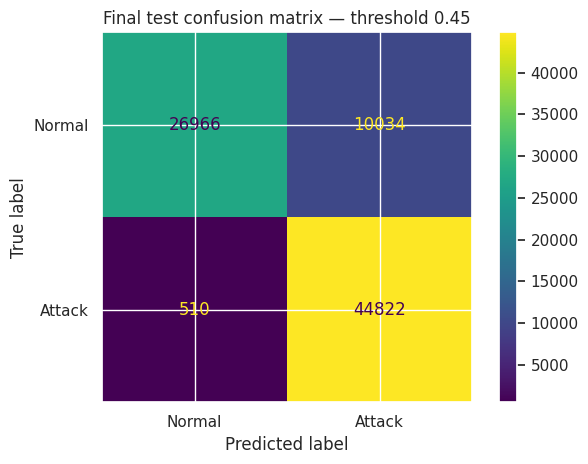

In [30]:
# Final predictions at the model's default threshold.
test_scores = tuned_pipeline.predict_proba(X_test)[:, 1]
test_pred_default = (test_scores >= 0.50).astype(int)
test_pred_selected = (test_scores >= SELECTED_THRESHOLD).astype(int)

test_metrics_default = calculate_metrics(y_test, test_pred_default, test_scores)
test_metrics_selected = calculate_metrics(y_test, test_pred_selected, test_scores)

final_test_results = pd.DataFrame([
    {"setting": "Tuned RF, threshold 0.50", **test_metrics_default},
    {"setting": f"Tuned RF, threshold {SELECTED_THRESHOLD:.2f}", **test_metrics_selected}
]).set_index("setting")

display(final_test_results.round(4))

print("\nClassification report at selected threshold:")
print(classification_report(
    y_test, test_pred_selected,
    labels=[0, 1],
    target_names=["Normal (0)", "Attack (1)"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred_selected,
    labels=[0, 1],
    display_labels=["Normal", "Attack"],
    values_format="d"
)
plt.title(f"Final test confusion matrix — threshold {SELECTED_THRESHOLD:.2f}")
plt.tight_layout()
plt.show()

## 20. Save the trained pipeline and metadata

Save the **whole pipeline**, not just the classifier. It includes imputation, scaling, encoding, and the model, which helps ensure that future predictions use the same preprocessing.

The `.joblib` file can be loaded by a Streamlit app. Only load model files you trust. The model directory is created locally in the Kaggle session; download the artifact or save it to a Kaggle Model/GitHub Release workflow if you want to use it elsewhere. Avoid committing large generated artifacts to GitHub without considering repository limits.

In [31]:
import joblib
import json

OUTPUT_DIR = Path("/kaggle/working/cybersentryfusion_artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_path = OUTPUT_DIR / "cybersentryfusion_random_forest_pipeline.joblib"
metadata_path = OUTPUT_DIR / "model_metadata.json"

joblib.dump(tuned_pipeline, model_path)

metadata = {
    "project": "CyberSentryFusion",
    "task": "binary network intrusion detection",
    "target_column": "label",
    "label_mapping": {"0": "Normal", "1": "Attack"},
    "input_features": feature_columns,
    "selected_model": "RandomForestClassifier (tuned with RandomizedSearchCV)",
    "selected_threshold": SELECTED_THRESHOLD,
    "threshold_selection": "validation F1-score",
    "random_state": RANDOM_STATE,
    "warning": "Trained on labelled UNSW-NB15 records; not a live traffic monitor."
}

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

print("Saved pipeline:", model_path)
print("Saved metadata:", metadata_path)
print("Artifacts directory contents:", list(OUTPUT_DIR.iterdir()))

Saved pipeline: /kaggle/working/cybersentryfusion_artifacts/cybersentryfusion_random_forest_pipeline.joblib
Saved metadata: /kaggle/working/cybersentryfusion_artifacts/model_metadata.json
Artifacts directory contents: [PosixPath('/kaggle/working/cybersentryfusion_artifacts/cybersentryfusion_random_forest_pipeline.joblib'), PosixPath('/kaggle/working/cybersentryfusion_artifacts/model_metadata.json')]


## 21. Test a saved pipeline on a few rows

This final check loads the artifact and makes predictions. We use rows from the existing test file only to verify that the saved pipeline behaves consistently; the evaluation metrics above remain the final test report.

In [32]:
loaded_pipeline = joblib.load(model_path)

sample_rows = X_test.head(5).copy()
sample_scores = loaded_pipeline.predict_proba(sample_rows)[:, 1]
sample_predictions = (sample_scores >= SELECTED_THRESHOLD).astype(int)

sample_output = pd.DataFrame({
    "attack_score": sample_scores,
    "predicted_label": sample_predictions,
    "predicted_class": np.where(sample_predictions == 1, "Attack", "Normal"),
    "actual_label_for_check": y_test.head(5).to_numpy()
})
display(sample_output)

,attack_score,predicted_label,predicted_class,actual_label_for_check
0,0.683224,1,Attack,0
1,0.507008,1,Attack,0
2,0.487888,1,Attack,0
3,0.735455,1,Attack,0
4,0.755415,1,Attack,0


## 22. Streamlit handoff checklist

Before building `app/streamlit_app.py`, confirm:
- The saved `.joblib` pipeline loads correctly.
- The app validates that required feature columns exist.
- Extra columns are ignored or handled explicitly; missing required columns trigger a clear error.
- The app uses the same `SELECTED_THRESHOLD` recorded in metadata.
- The app labels predictions clearly as model outputs, not certainty.
- The app does not claim to monitor live network traffic unless a real traffic collection pipeline is added.
- Large files and datasets are not committed to the repository unnecessarily.

A simple Streamlit app can load the pipeline and accept a CSV. It does not require a separate FastAPI backend for this use case.

## 23. Experiment log and conclusions

Fill this in after running the notebook. Do not write metrics before they are produced by your own run.

### Experiment log
- Dataset/version:
- Kaggle notebook date:
- Data cleaning decisions:
- Baseline validation results:
- Best candidate model:
- Best cross-validation score:
- Validation-selected threshold:
- Final test precision / recall / F1:
- Final test false-positive rate:
- Main error pattern:
- Most important features:
- Runtime limitations or sampling used:

### Questions to answer in your own words
1. Why do we drop `id` and `attack_cat` from model inputs?
2. Why do we split the training file into training and validation subsets?
3. Why is preprocessing inside a pipeline?
4. What does attack recall mean in this project?
5. What happens to false positives when we lower the threshold?
6. Why must we avoid tuning on the final test set?
7. What does permutation importance tell us, and what does it *not* tell us?
8. Why does the Streamlit app need the saved preprocessing pipeline as well as the model?
9. Why is a dataset-based prediction not the same as live intrusion detection?

### Final reminder
A strong project is not the one with the most models or the biggest dashboard. It is the one with a defensible experiment design, honest evaluation, understandable code, and clearly stated limitations.